### Etapa 01 — Conexão e caminhos

Usa a pasta `dados` gerada no notebook 02 (`treino` e `validacao`, uma subpasta por categoria).

In [1]:
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    pasta_projeto = Path('/content/drive/Shareddrives/COMPUTER VISION_TURMA 2026/PROJETO FINAL/GRUPO C/Projeto — Placas Mercosul')
except ImportError:
    pasta_projeto = Path('.').resolve()

pasta_dados = pasta_projeto / 'dados'
pasta_resultados = pasta_projeto / 'resultados'
pasta_resultados.mkdir(exist_ok=True)

print('Dados:', pasta_dados, pasta_dados.exists())

Dados: C:\Users\USER\Downloads\Projeto — Placas Mercosul-20261106T140915Z-1-001\Entrega — Placas Mercosul\dados True


In [2]:
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

ORDEM = ['mercosul', 'tradicional', 'mercosul moto', 'tradicional moto']
CORES = {'mercosul': '#2a6fdb', 'tradicional': '#8c8c8c', 'mercosul moto': '#7fb3ff', 'tradicional moto': '#d08b3a'}
SEMENTE = 42
dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
sns.set_theme(style='whitegrid')

print('Dispositivo:', dispositivo)

Dispositivo: cuda


### Etapa 02 — Leitura dos recortes

Uma passada por todos os arquivos: guarda largura, altura e média de cada canal RGB, acumula o histograma de cores por categoria e já ajusta cada recorte para 64 × 128 sem distorcer (bordas pretas).

In [3]:
ALTURA, LARGURA = 64, 128

registros, imagens = [], []
histogramas = {c: np.zeros((3, 256)) for c in ORDEM}

for caminho in tqdm(sorted(pasta_dados.glob('*/*/*.jpg'))):
    conjunto, categoria = caminho.parts[-3], caminho.parts[-2]
    with Image.open(caminho) as img:
        img = img.convert('RGB')
    pixels = np.asarray(img)
    for canal in range(3):
        histogramas[categoria][canal] += np.bincount(pixels[..., canal].ravel(), minlength=256)
    media = pixels.reshape(-1, 3).mean(0)
    registros.append({'conjunto': conjunto, 'categoria': categoria, 'arquivo': caminho.name, 'largura': img.width, 'altura': img.height,
                      'R': media[0], 'G': media[1], 'B': media[2]})
    imagens.append(np.asarray(ImageOps.pad(img, (LARGURA, ALTURA), color=(0, 0, 0))))

recortes = pd.DataFrame(registros)
recortes['proporcao'] = recortes['largura'] / recortes['altura']
recortes['rotulo'] = recortes['categoria'].map({c: i for i, c in enumerate(ORDEM)})
imagens = np.stack(imagens)

print(recortes.shape, imagens.shape)
display(recortes.head())

  0%|          | 0/20205 [00:00<?, ?it/s]

(20205, 10) (20205, 64, 128, 3)


,conjunto,categoria,arquivo,largura,altura,R,G,B,proporcao,rotulo
0,treino,mercosul,CBD_0274680084A20000000058_20240327090459981_C...,166,77,57.455171,66.075575,86.484275,2.155844,0
1,treino,mercosul,CBD_0274680084A20000000066_20240401114255803_C...,96,47,149.539672,146.669770,159.411348,2.042553,0
2,treino,mercosul,CBD_0274680084A20000000070_20240403105347177_C...,48,15,63.427778,69.358333,99.037500,3.200000,0
3,treino,mercosul,CBD_0274680084A20000000070_20240403105347177_C...,136,47,75.198373,81.068680,103.348874,2.893617,0
4,treino,mercosul,CBD_0274680084A20000000070_20240403105347177_C...,43,11,95.887949,98.133192,113.556025,3.909091,0


### Etapa 03 — Distribuição das categorias

conjunto,treino,validacao,total,%
categoria,,,,
mercosul,6934,2973,9907,49.0
tradicional,5123,2196,7319,36.2
mercosul moto,1533,658,2191,10.8
tradicional moto,551,237,788,3.9


Maior categoria / menor categoria: 12.6x


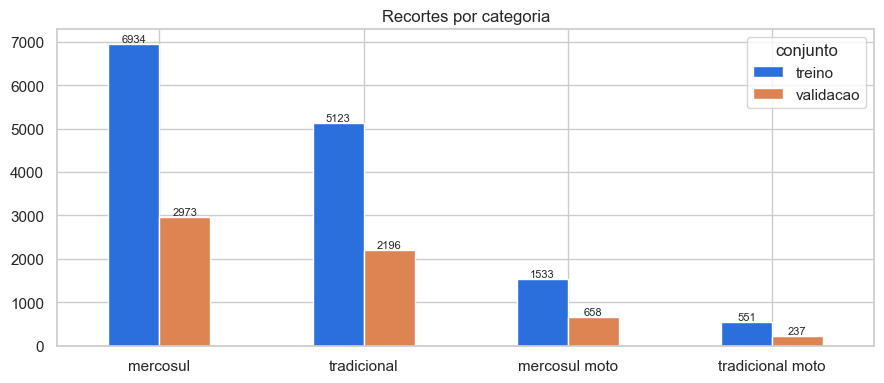

In [4]:
contagem = pd.crosstab(recortes['categoria'], recortes['conjunto']).reindex(ORDEM)
contagem['total'] = contagem.sum(1)
contagem['%'] = (contagem['total'] / contagem['total'].sum() * 100).round(1)
display(contagem)
print(f'Maior categoria / menor categoria: {contagem["total"].max() / contagem["total"].min():.1f}x')

fig, tela = plt.subplots(figsize=(9, 4))
contagem[['treino', 'validacao']].plot.bar(ax=tela, rot=0, color=['#2a6fdb', '#dd8452'])
for barra in tela.patches:
    tela.annotate(f'{barra.get_height():.0f}', (barra.get_x() + barra.get_width() / 2, barra.get_height()), ha='center', va='bottom', fontsize=8)
tela.set_xlabel('')
tela.set_title('Recortes por categoria')
plt.tight_layout()
fig.savefig(pasta_resultados / 'eda_categorias.png', dpi=150, bbox_inches='tight')
plt.show()

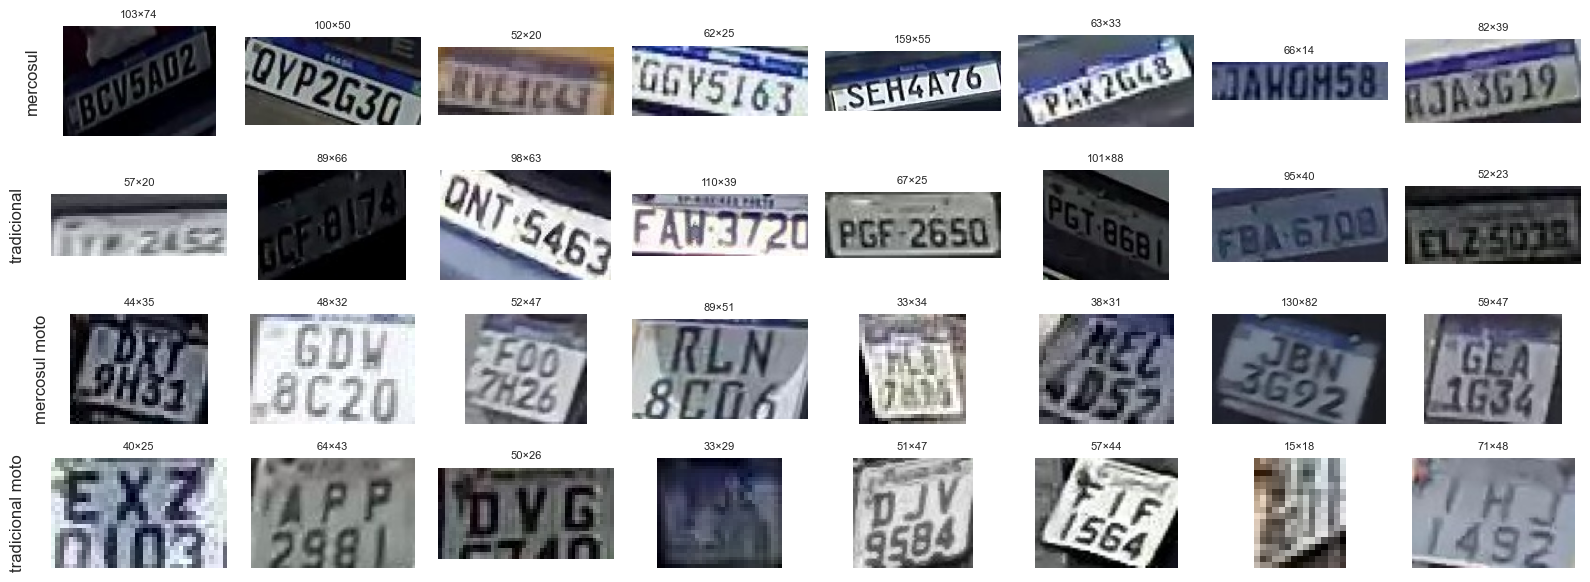

In [5]:
fig, telas = plt.subplots(4, 8, figsize=(16, 6))
for linha, categoria in enumerate(ORDEM):
    amostra = recortes[recortes['categoria'] == categoria].sample(8, random_state=SEMENTE)
    for coluna, (i, l) in enumerate(amostra.iterrows()):
        telas[linha, coluna].imshow(Image.open(pasta_dados / l['conjunto'] / categoria / l['arquivo']))
        telas[linha, coluna].set_title(f'{l["largura"]}×{l["altura"]}', fontsize=8)
        telas[linha, coluna].axis('off')
    telas[linha, 0].text(-0.15, 0.5, categoria, transform=telas[linha, 0].transAxes, rotation=90, ha='right', va='center')
plt.tight_layout()
plt.show()

### Etapa 04 — Largura, altura e proporção

categoria        mercosul  tradicional  mercosul moto  tradicional moto
largura   count    9907.0       7319.0         2191.0             788.0
          mean       76.3         76.8           58.3              55.3
          std        41.8         40.2           19.8              25.7
          min         1.0          8.0           13.0               1.0
          25%        51.0         51.0           45.0              41.0
          50%        69.0         70.0           55.0              51.0
          75%        93.0         95.0           68.0              65.0
          max      1224.0       1104.0          211.0             493.0
altura    count    9907.0       7319.0         2191.0             788.0
          mean       34.7         35.8           48.9              43.4
          std        22.8         21.4           18.6              18.3
          min         1.0          4.0           11.0               1.0
          25%        20.0         20.0           36.0              31.0
          50%        30.0         31.0           46.0              40.0
          75%        44.0         46.0           59.0              53.0
          max       546.0        351.0          188.0             171.0
proporcao count    9907.0       7319.0         2191.0             788.0
          mean        2.5          2.4            1.2               1.3
          std         0.9          0.9            0.3               0.5
          min         0.3          0.4            0.6               0.7
          25%         1.8          1.8            1.1               1.1
          50%         2.4          2.3            1.2               1.3
          75%         3.0          2.9            1.4               1.5
          max        22.0         22.3            4.4              13.7

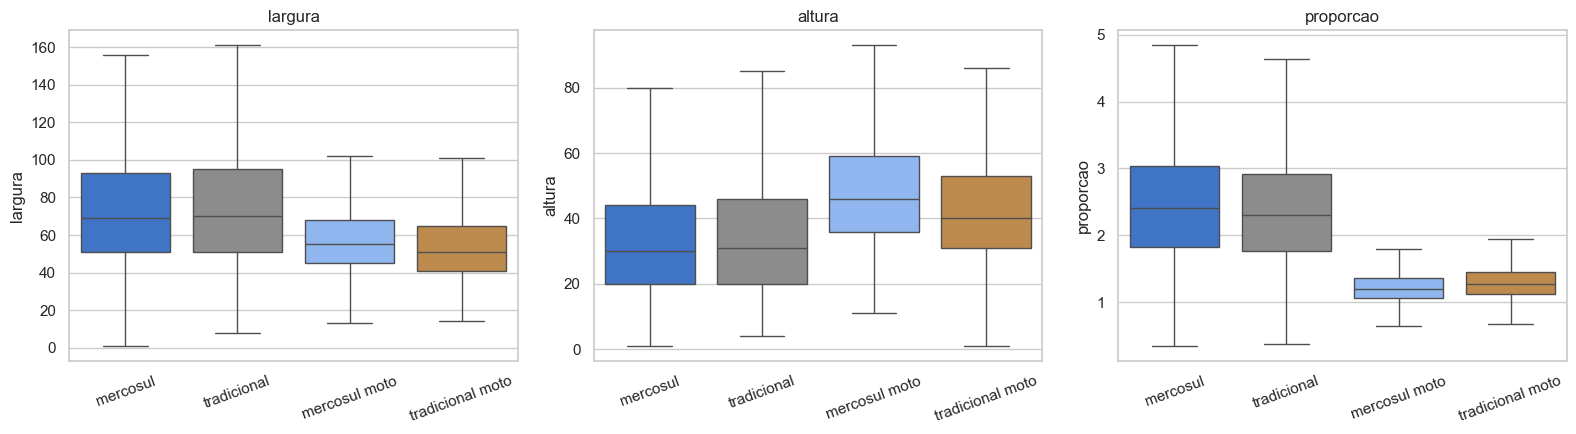

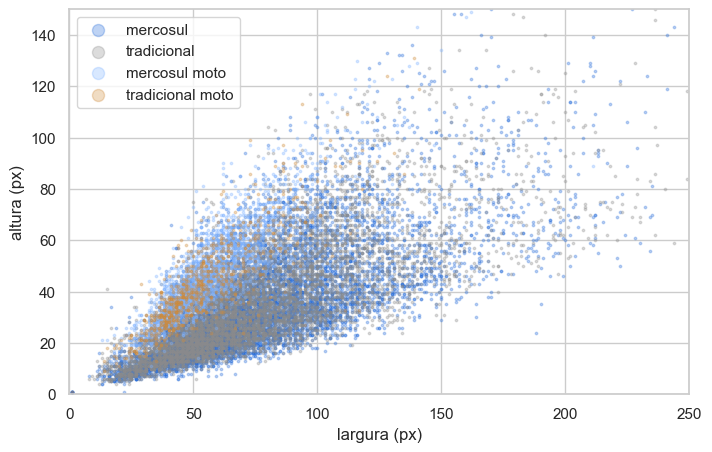

Recortes com menos de 20 px de altura: 20.7%


In [6]:
display(recortes.groupby('categoria')[['largura', 'altura', 'proporcao']].describe().loc[ORDEM].round(1).T)

fig, telas = plt.subplots(1, 3, figsize=(16, 4.5))
for tela, coluna in zip(telas, ['largura', 'altura', 'proporcao']):
    sns.boxplot(data=recortes, x='categoria', y=coluna, order=ORDEM, hue='categoria', palette=CORES, ax=tela, showfliers=False)
    tela.set_xlabel('')
    tela.tick_params(axis='x', rotation=20)
    tela.set_title(coluna)
plt.tight_layout()
fig.savefig(pasta_resultados / 'eda_dimensoes.png', dpi=150, bbox_inches='tight')
plt.show()

fig, tela = plt.subplots(figsize=(8, 5))
for categoria in ORDEM:
    parte = recortes[recortes['categoria'] == categoria]
    tela.scatter(parte['largura'], parte['altura'], s=3, alpha=0.3, color=CORES[categoria], label=categoria)
tela.set_xlim(0, 250)
tela.set_ylim(0, 150)
tela.set_xlabel('largura (px)')
tela.set_ylabel('altura (px)')
tela.legend(markerscale=5)
plt.show()

print(f'Recortes com menos de 20 px de altura: {(recortes["altura"] < 20).mean():.1%}')

### Etapa 05 — Canais RGB

,R,G,B
categoria,,,
mercosul,112.3,114.9,125.7
tradicional,110.5,107.6,111.5
mercosul moto,135.7,138.9,146.6
tradicional moto,127.1,128.3,129.7


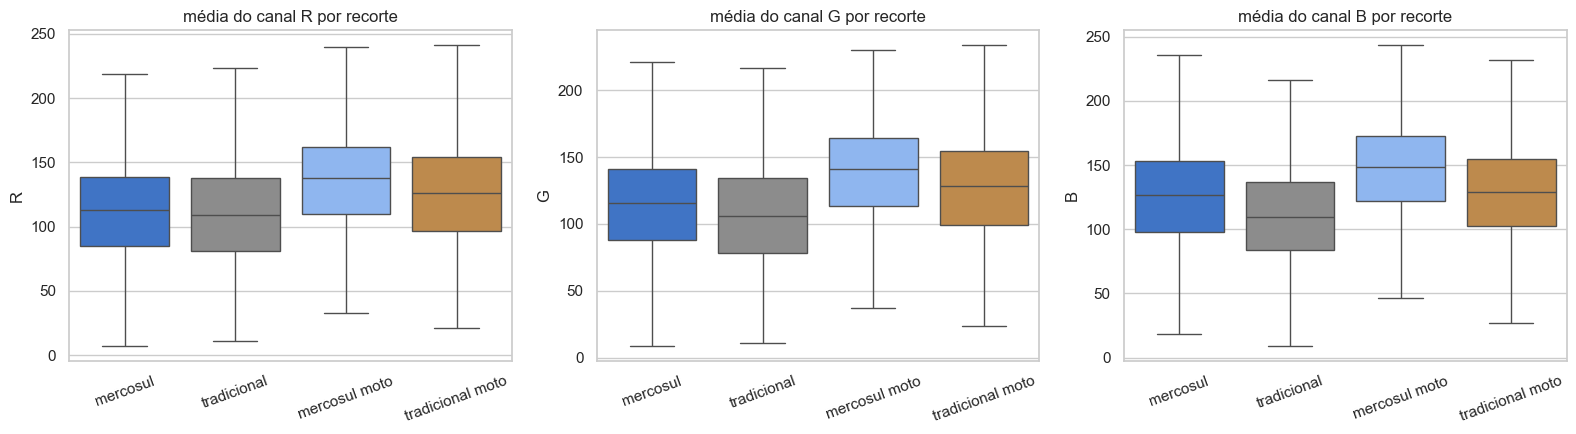

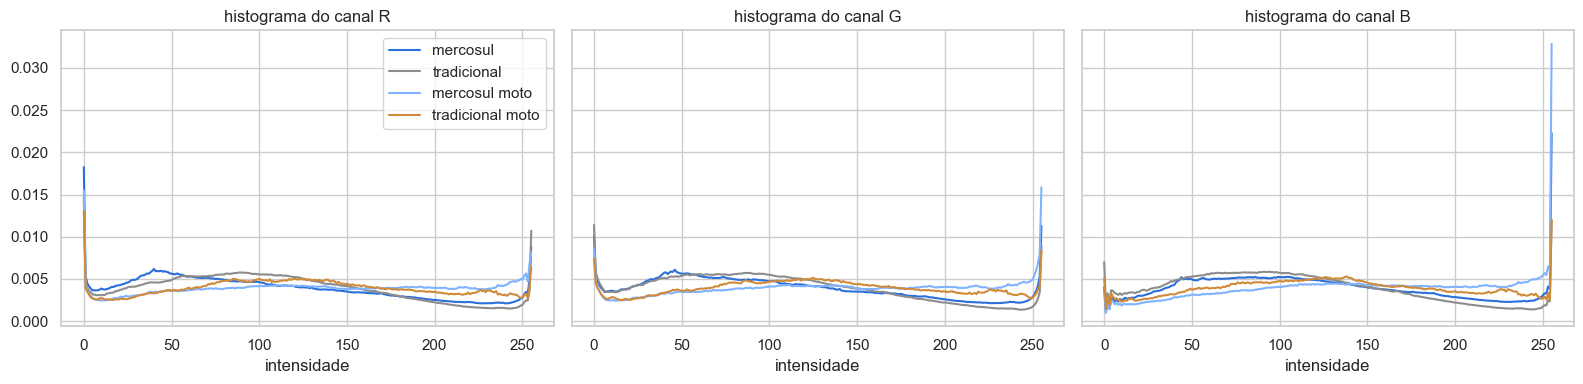

In [7]:
display(recortes.groupby('categoria')[['R', 'G', 'B']].mean().loc[ORDEM].round(1))

fig, telas = plt.subplots(1, 3, figsize=(16, 4.5))
for tela, canal in zip(telas, ['R', 'G', 'B']):
    sns.boxplot(data=recortes, x='categoria', y=canal, order=ORDEM, hue='categoria', palette=CORES, ax=tela, showfliers=False)
    tela.set_xlabel('')
    tela.tick_params(axis='x', rotation=20)
    tela.set_title(f'média do canal {canal} por recorte')
plt.tight_layout()
fig.savefig(pasta_resultados / 'eda_canais_rgb.png', dpi=150, bbox_inches='tight')
plt.show()

fig, telas = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for canal, (tela, nome) in enumerate(zip(telas, ['R', 'G', 'B'])):
    for categoria in ORDEM:
        tela.plot(histogramas[categoria][canal] / histogramas[categoria][canal].sum(), color=CORES[categoria], label=categoria)
    tela.set_title(f'histograma do canal {nome}')
    tela.set_xlabel('intensidade')
telas[0].legend()
plt.tight_layout()
fig.savefig(pasta_resultados / 'eda_histogramas_rgb.png', dpi=150, bbox_inches='tight')
plt.show()

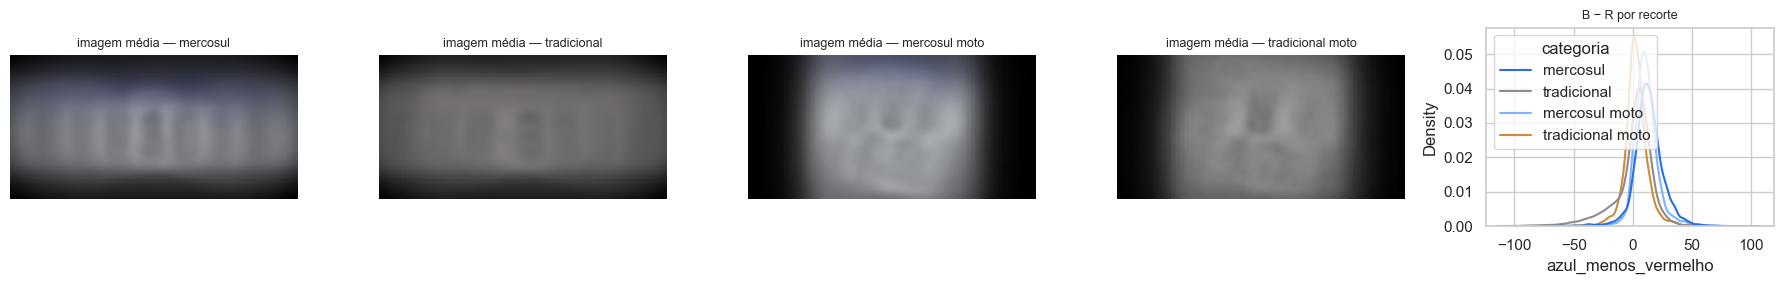

In [8]:
recortes['azul_menos_vermelho'] = recortes['B'] - recortes['R']

fig, telas = plt.subplots(1, 5, figsize=(18, 3))
for tela, categoria in zip(telas, ORDEM):
    tela.imshow(imagens[recortes['categoria'] == categoria].mean(0).astype(np.uint8))
    tela.set_title(f'imagem média — {categoria}', fontsize=9)
    tela.axis('off')
sns.kdeplot(data=recortes, x='azul_menos_vermelho', hue='categoria', hue_order=ORDEM, palette=CORES, common_norm=False, ax=telas[4])
telas[4].set_title('B − R por recorte', fontsize=9)
plt.tight_layout()
plt.show()

### Etapa 06 — Tensores e normalização

Os recortes ficam em memória como `uint8`. A média e o desvio de cada canal são calculados só no treino.

In [9]:
X = torch.from_numpy(imagens).permute(0, 3, 1, 2).contiguous().to(dispositivo)
y = torch.from_numpy(recortes['rotulo'].to_numpy()).to(dispositivo)
rotulos = recortes['rotulo'].to_numpy()

indices_treino = np.where(recortes['conjunto'] == 'treino')[0]
indices_validacao = np.where(recortes['conjunto'] == 'validacao')[0]

amostra = X[indices_treino[::10]].float() / 255
MEDIA = amostra.mean((0, 2, 3)).view(1, 3, 1, 1)
DESVIO = amostra.std((0, 2, 3)).view(1, 3, 1, 1)

print('Média:', MEDIA.flatten().cpu().numpy().round(3), '| Desvio:', DESVIO.flatten().cpu().numpy().round(3))

Média: [0.325 0.326 0.348] | Desvio: [0.304 0.304 0.309]


### Etapa 07 — Balanceamento por reamostragem

- **oversampling:** as categorias menores são sorteadas com reposição até ficarem do tamanho da maior;
- **undersampling:** as maiores são reduzidas ao tamanho da menor.

A reamostragem é feita só no treino.

,sem reamostragem,oversampling,undersampling
mercosul,6934,6934,551
tradicional,5123,6934,551
mercosul moto,1533,6934,551
tradicional moto,551,6934,551


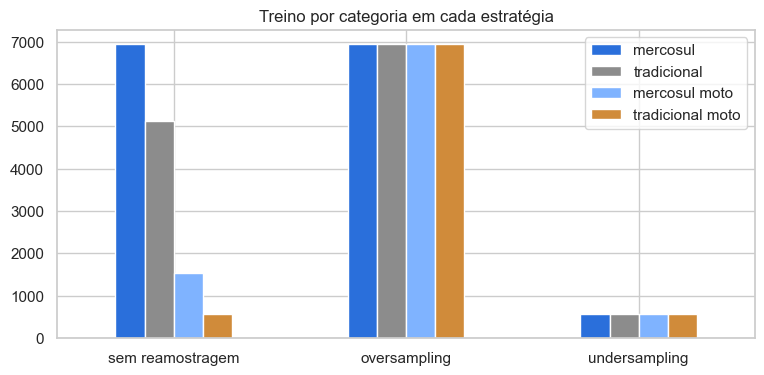

In [10]:
def reamostrar(indices, modo, semente=SEMENTE):
    if modo == 'sem reamostragem':
        return indices
    gerador = np.random.default_rng(semente)
    partes = [indices[rotulos[indices] == c] for c in range(len(ORDEM))]
    if modo == 'oversampling':
        alvo = max(len(p) for p in partes)
        return np.concatenate([np.concatenate([p, gerador.choice(p, alvo - len(p))]) for p in partes])
    alvo = min(len(p) for p in partes)
    return np.concatenate([gerador.choice(p, alvo, replace=False) for p in partes])

MODOS = ['sem reamostragem', 'oversampling', 'undersampling']
tamanhos = pd.DataFrame({modo: np.bincount(rotulos[reamostrar(indices_treino, modo)], minlength=4) for modo in MODOS}, index=ORDEM)
display(tamanhos)

tamanhos.T.plot.bar(figsize=(9, 4), rot=0, color=[CORES[c] for c in ORDEM], title='Treino por categoria em cada estratégia')
plt.show()

### Etapa 08 — CNN do zero, camada por camada

A rede é montada a partir de uma lista de blocos. Cada bloco é `conv 3×3 → (BatchNorm) → ReLU`, repetido 1 ou 2 vezes, seguido de `MaxPool 2×2`. No fim, média global, dropout e uma camada linear com 4 saídas.

Os experimentos vão adicionando uma coisa de cada vez. Todos usam oversampling e 12 épocas.

In [11]:
def montar_rede(canais, batchnorm=False, convs_por_bloco=1, dropout=0.0):
    camadas, entrada = [], 3
    for saida in canais:
        for _ in range(convs_por_bloco):
            camadas += [nn.Conv2d(entrada, saida, 3, padding=1)]
            camadas += [nn.BatchNorm2d(saida)] if batchnorm else []
            camadas += [nn.ReLU(inplace=True)]
            entrada = saida
        camadas += [nn.MaxPool2d(2)]
    camadas += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(entrada, len(ORDEM))]
    return nn.Sequential(*camadas)

def prever(rede, indices):
    rede.eval()
    saidas = []
    with torch.no_grad(), torch.autocast(dispositivo, enabled=dispositivo == 'cuda'):
        for k in range(0, len(indices), 1024):
            saidas.append(rede((X[indices[k:k + 1024]].float() / 255 - MEDIA) / DESVIO).float().softmax(1))
    return torch.cat(saidas).cpu().numpy()

def treinar(config, modo='oversampling', epocas=12, lote=128, taxa=3e-3, decaimento=1e-4):
    torch.manual_seed(SEMENTE)
    rede = montar_rede(**config).to(dispositivo)
    indices = torch.from_numpy(reamostrar(indices_treino, modo)).to(dispositivo)
    passos = math.ceil(len(indices) / lote)
    otimizador = torch.optim.AdamW(rede.parameters(), lr=taxa, weight_decay=decaimento)
    agendador = torch.optim.lr_scheduler.OneCycleLR(otimizador, max_lr=taxa, total_steps=epocas * passos)
    escalador = torch.amp.GradScaler(enabled=dispositivo == 'cuda')

    historico, melhor = [], {'f1': -1}
    inicio = time.time()
    for epoca in range(1, epocas + 1):
        rede.train()
        ordem = indices[torch.randperm(len(indices), device=dispositivo)]
        for k in range(passos):
            lote_atual = ordem[k * lote:(k + 1) * lote]
            x = (X[lote_atual].float() / 255 - MEDIA) / DESVIO
            with torch.autocast(dispositivo, enabled=dispositivo == 'cuda'):
                perda = F.cross_entropy(rede(x), y[lote_atual])
            otimizador.zero_grad()
            escalador.scale(perda).backward()
            escalador.step(otimizador)
            escalador.update()
            agendador.step()

        registro = {'epoca': epoca}
        for nome, conjunto in [('treino', indices_treino), ('validacao', indices_validacao)]:
            prob = prever(rede, conjunto)
            registro[f'perda_{nome}'] = F.nll_loss(torch.from_numpy(np.log(prob + 1e-7)), torch.from_numpy(rotulos[conjunto])).item()
            registro[f'acuracia_{nome}'] = accuracy_score(rotulos[conjunto], prob.argmax(1))
        f1 = registro['f1_validacao'] = f1_score(rotulos[indices_validacao], prob.argmax(1), average='macro')
        historico.append(registro)
        if f1 > melhor['f1']:
            melhor = {'f1': f1, 'epoca': epoca, 'estado': {k: v.detach().clone() for k, v in rede.state_dict().items()}}

    rede.load_state_dict(melhor['estado'])
    return rede, pd.DataFrame(historico), {'f1_macro': melhor['f1'], 'melhor_epoca': melhor['epoca'], 'tempo_s': time.time() - inicio,
                                           'parametros': sum(p.numel() for p in rede.parameters())}

In [12]:
EXPERIMENTOS = {
    '1 bloco (16)': dict(canais=[16]),
    '2 blocos (16-32)': dict(canais=[16, 32]),
    '3 blocos (16-32-64)': dict(canais=[16, 32, 64]),
    '4 blocos (16-32-64-128)': dict(canais=[16, 32, 64, 128]),
    '+ BatchNorm': dict(canais=[16, 32, 64, 128], batchnorm=True),
    '+ 2 convs por bloco': dict(canais=[16, 32, 64, 128], batchnorm=True, convs_por_bloco=2),
    '+ Dropout 0.3': dict(canais=[16, 32, 64, 128], batchnorm=True, convs_por_bloco=2, dropout=0.3),
    '5 blocos (…-256)': dict(canais=[16, 32, 64, 128, 256], batchnorm=True, convs_por_bloco=2, dropout=0.3),
}

resultados = []
for nome, config in EXPERIMENTOS.items():
    _, historico, resumo = treinar(config)
    resultados.append({'experimento': nome, **resumo})
    print(f'{nome:26s} | F1 macro {resumo["f1_macro"]:.4f} | {resumo["parametros"]:>9,} parâmetros | {resumo["tempo_s"]:.0f}s')

experimentos = pd.DataFrame(resultados)
experimentos.to_csv(pasta_resultados / 'cnn_experimentos.csv', index=False)

1 bloco (16)               | F1 macro 0.5963 |       516 parâmetros | 15s


2 blocos (16-32)           | F1 macro 0.7367 |     5,220 parâmetros | 23s


3 blocos (16-32-64)        | F1 macro 0.8489 |    23,844 parâmetros | 27s


4 blocos (16-32-64-128)    | F1 macro 0.8798 |    97,956 parâmetros | 30s


+ BatchNorm                | F1 macro 0.8789 |    98,436 parâmetros | 38s


+ 2 convs por bloco        | F1 macro 0.8818 |   294,996 parâmetros | 78s


+ Dropout 0.3              | F1 macro 0.8877 |   294,996 parâmetros | 78s


5 blocos (…-256)           | F1 macro 0.8823 | 1,181,780 parâmetros | 85s


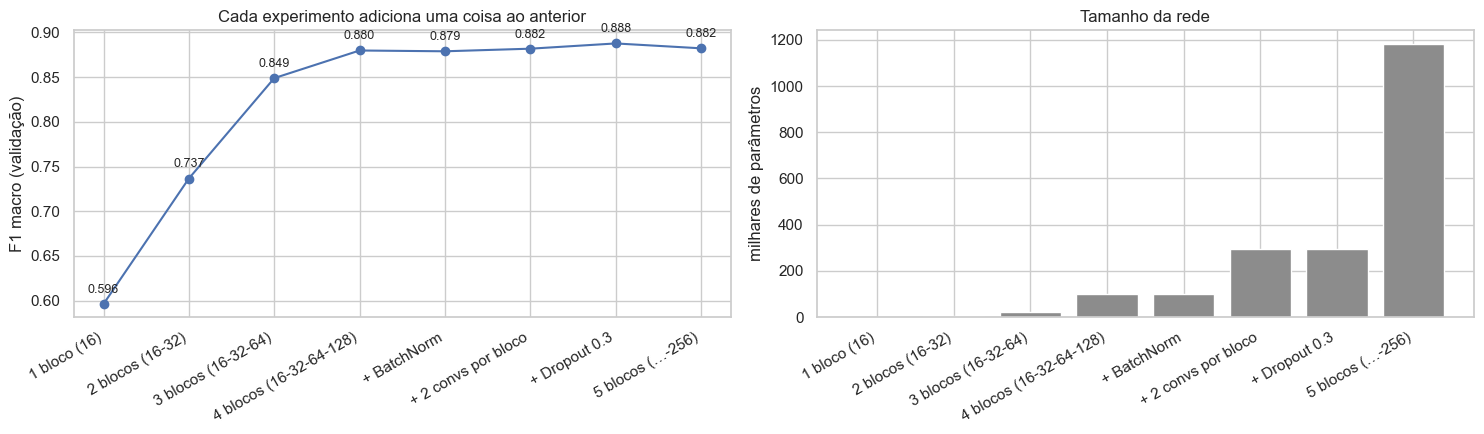

Maior F1: + Dropout 0.3


In [13]:
fig, telas = plt.subplots(1, 2, figsize=(15, 4.5))
telas[0].plot(experimentos['experimento'], experimentos['f1_macro'], marker='o')
for i, valor in enumerate(experimentos['f1_macro']):
    telas[0].annotate(f'{valor:.3f}', (i, valor), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
telas[0].set_ylabel('F1 macro (validação)')
telas[0].set_title('Cada experimento adiciona uma coisa ao anterior')
telas[1].bar(experimentos['experimento'], experimentos['parametros'] / 1e3, color='#8c8c8c')
telas[1].set_ylabel('milhares de parâmetros')
telas[1].set_title('Tamanho da rede')
for tela in telas:
    tela.tick_params(axis='x', rotation=30)
    plt.setp(tela.get_xticklabels(), ha='right')
plt.tight_layout()
fig.savefig(pasta_resultados / 'cnn_experimentos.png', dpi=150, bbox_inches='tight')
plt.show()

print('Maior F1:', experimentos.loc[experimentos['f1_macro'].idxmax(), 'experimento'])

### Etapa 09 — Rede simples

Sem aumento de dados, as redes maiores decoram o treino: a acurácia de treino chega a 100% e a perda de validação sobe. A partir de 4 blocos o ganho de F1 é pequeno, então a rede final é a de 4 blocos com **metade dos canais (8-16-32-64)**, 1 convolução por bloco, BatchNorm, dropout 0.3, weight decay 1e-3 e 15 épocas.

In [14]:
MODELO = dict(canais=[8, 16, 32, 64], batchnorm=True, dropout=0.3)
TREINO = dict(epocas=15, decaimento=1e-3)

print(montar_rede(**MODELO))
print(f'{sum(p.numel() for p in montar_rede(**MODELO).parameters()):,} parâmetros')

Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU(inplace=True)
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU(inplace=True)
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (14): ReLU(inplace=Tru

### Etapa 10 — Com e sem reamostragem

A rede simples é treinada com as três estratégias da Etapa 07.

,estrategia,treino,f1_macro,acuracia,acuracia_balanceada,recall mercosul,recall tradicional,recall mercosul moto,recall tradicional moto
0,sem reamostragem,14141,0.8733,0.9136,0.8909,0.9105,0.9253,0.9301,0.7975
1,oversampling,27736,0.8767,0.9139,0.9065,0.9031,0.9271,0.9392,0.8565
2,undersampling,2204,0.7981,0.8466,0.8398,0.8833,0.7933,0.8723,0.8101


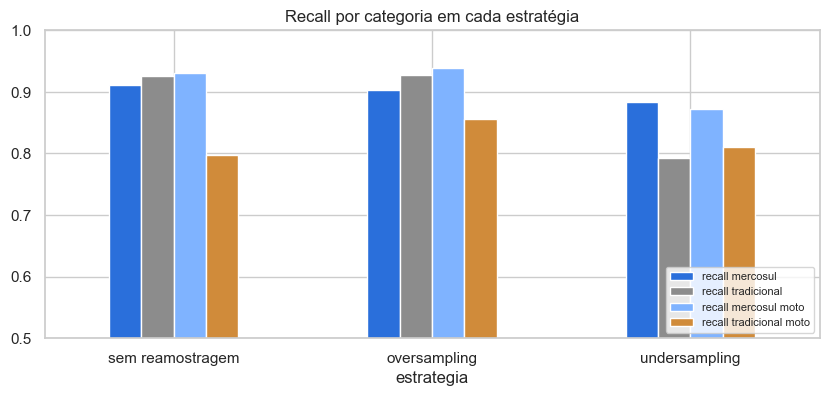

In [15]:
balanceamento = []
for modo in MODOS:
    rede_modo, _, _ = treinar(MODELO, modo, **TREINO)
    previsto = prever(rede_modo, indices_validacao).argmax(1)
    recall = (confusion_matrix(rotulos[indices_validacao], previsto, normalize='true').diagonal())
    balanceamento.append({'estrategia': modo, 'treino': len(reamostrar(indices_treino, modo)),
                          'f1_macro': f1_score(rotulos[indices_validacao], previsto, average='macro'),
                          'acuracia': accuracy_score(rotulos[indices_validacao], previsto),
                          'acuracia_balanceada': balanced_accuracy_score(rotulos[indices_validacao], previsto),
                          **{f'recall {c}': r for c, r in zip(ORDEM, recall)}})

balanceamento = pd.DataFrame(balanceamento)
balanceamento.to_csv(pasta_resultados / 'cnn_balanceamento.csv', index=False)
display(balanceamento.round(4))

balanceamento.set_index('estrategia')[[f'recall {c}' for c in ORDEM]].plot.bar(figsize=(10, 4), rot=0, color=[CORES[c] for c in ORDEM], ylim=(0.5, 1), title='Recall por categoria em cada estratégia')
plt.legend(loc='lower right', fontsize=8)
plt.savefig(pasta_resultados / 'cnn_balanceamento.png', dpi=150, bbox_inches='tight')
plt.show()

### Etapa 11 — Modelo final

Rede simples com **oversampling**, 15 épocas. As curvas de treino e validação são medidas do mesmo jeito (modo de avaliação, treino sem as cópias do oversampling) para comparar o overfitting.

oversampling | melhor época 15 | F1 macro 0.8767 | 45s


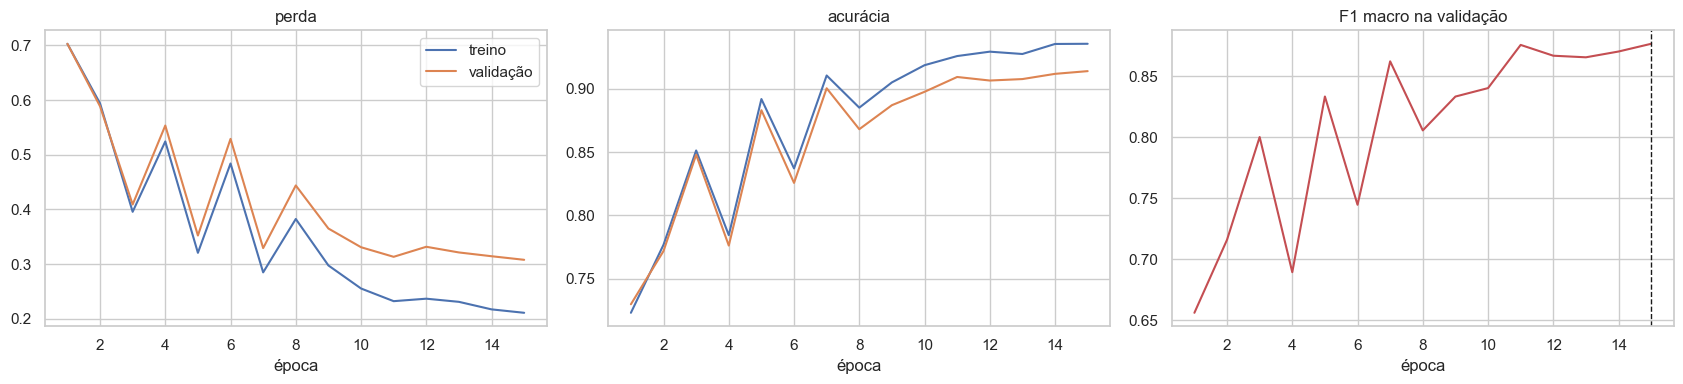

In [16]:
melhor_modo = 'oversampling'
rede, historico, resumo = treinar(MODELO, melhor_modo, **TREINO)
print(f'{melhor_modo} | melhor época {resumo["melhor_epoca"]} | F1 macro {resumo["f1_macro"]:.4f} | {resumo["tempo_s"]:.0f}s')
historico.to_csv(pasta_resultados / 'cnn_historico.csv', index=False)

torch.save({'config': MODELO, 'estrategia': melhor_modo, 'categorias': ORDEM, 'entrada': (ALTURA, LARGURA),
            'media': MEDIA.flatten().cpu(), 'desvio': DESVIO.flatten().cpu(), 'pesos': rede.state_dict()}, pasta_resultados / 'cnn_do_zero.pt')

fig, telas = plt.subplots(1, 3, figsize=(17, 4))
telas[0].plot(historico['epoca'], historico['perda_treino'], label='treino')
telas[0].plot(historico['epoca'], historico['perda_validacao'], label='validação')
telas[0].set_title('perda')
telas[1].plot(historico['epoca'], historico['acuracia_treino'], label='treino')
telas[1].plot(historico['epoca'], historico['acuracia_validacao'], label='validação')
telas[1].set_title('acurácia')
telas[2].plot(historico['epoca'], historico['f1_validacao'], color='#c44e52')
telas[2].axvline(resumo['melhor_epoca'], ls='--', color='k', lw=1)
telas[2].set_title('F1 macro na validação')
for tela in telas:
    tela.set_xlabel('época')
telas[0].legend()
plt.tight_layout()
fig.savefig(pasta_resultados / 'cnn_curvas.png', dpi=150, bbox_inches='tight')
plt.show()

### Etapa 12 — Métricas

,validação
acurácia,0.9139
acurácia balanceada,0.9065
F1 macro,0.8767
F1 ponderado,0.9150


                  precision    recall  f1-score   support

        mercosul      0.962     0.903     0.932      2973
     tradicional      0.905     0.927     0.916      2196
   mercosul moto      0.841     0.939     0.887       658
tradicional moto      0.702     0.857     0.772       237

        accuracy                          0.914      6064
       macro avg      0.853     0.907     0.877      6064
    weighted avg      0.918     0.914     0.915      6064



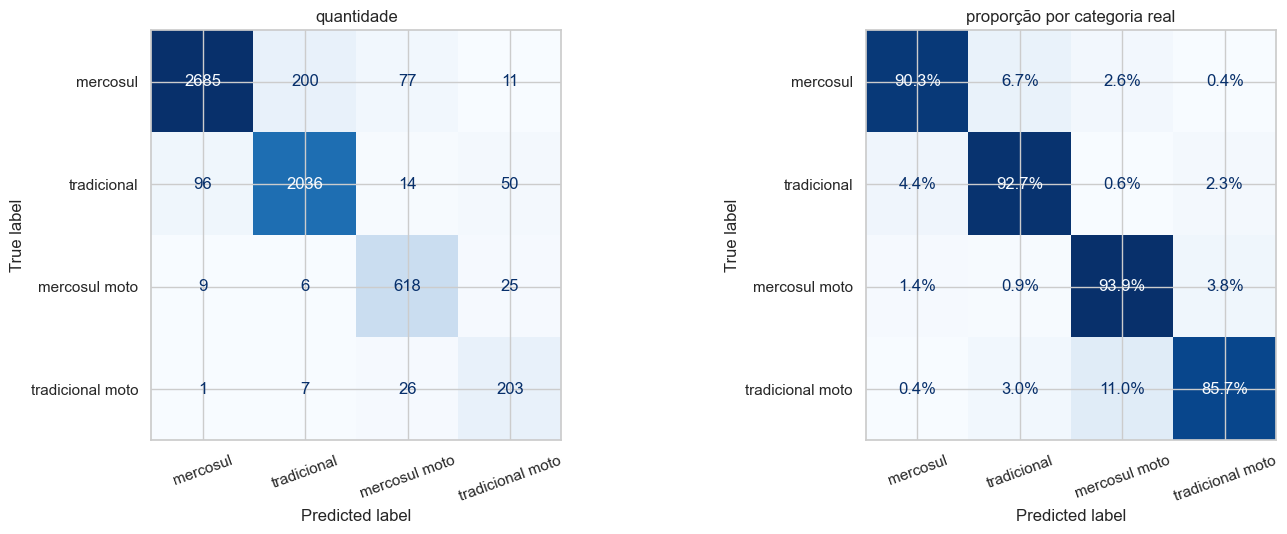

In [17]:
probabilidades = prever(rede, indices_validacao)
previsto = probabilidades.argmax(1)
real = rotulos[indices_validacao]

metricas = pd.Series({'acurácia': accuracy_score(real, previsto), 'acurácia balanceada': balanced_accuracy_score(real, previsto),
                      'F1 macro': f1_score(real, previsto, average='macro'), 'F1 ponderado': f1_score(real, previsto, average='weighted')})
display(metricas.round(4).to_frame('validação'))
print(classification_report(real, previsto, target_names=ORDEM, digits=3))

fig, telas = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay(confusion_matrix(real, previsto), display_labels=ORDEM).plot(ax=telas[0], cmap='Blues', colorbar=False, xticks_rotation=20)
ConfusionMatrixDisplay(confusion_matrix(real, previsto, normalize='true'), display_labels=ORDEM).plot(ax=telas[1], cmap='Blues', colorbar=False, xticks_rotation=20, values_format='.1%')
telas[0].set_title('quantidade')
telas[1].set_title('proporção por categoria real')
plt.tight_layout()
fig.savefig(pasta_resultados / 'cnn_matriz_confusao.png', dpi=150, bbox_inches='tight')
plt.show()

,,erros
categoria,previsto,
mercosul,tradicional,200
tradicional,mercosul,96
mercosul,mercosul moto,77
tradicional,tradicional moto,50
tradicional moto,mercosul moto,26
mercosul moto,tradicional moto,25
tradicional,mercosul moto,14
mercosul,tradicional moto,11
mercosul moto,mercosul,9


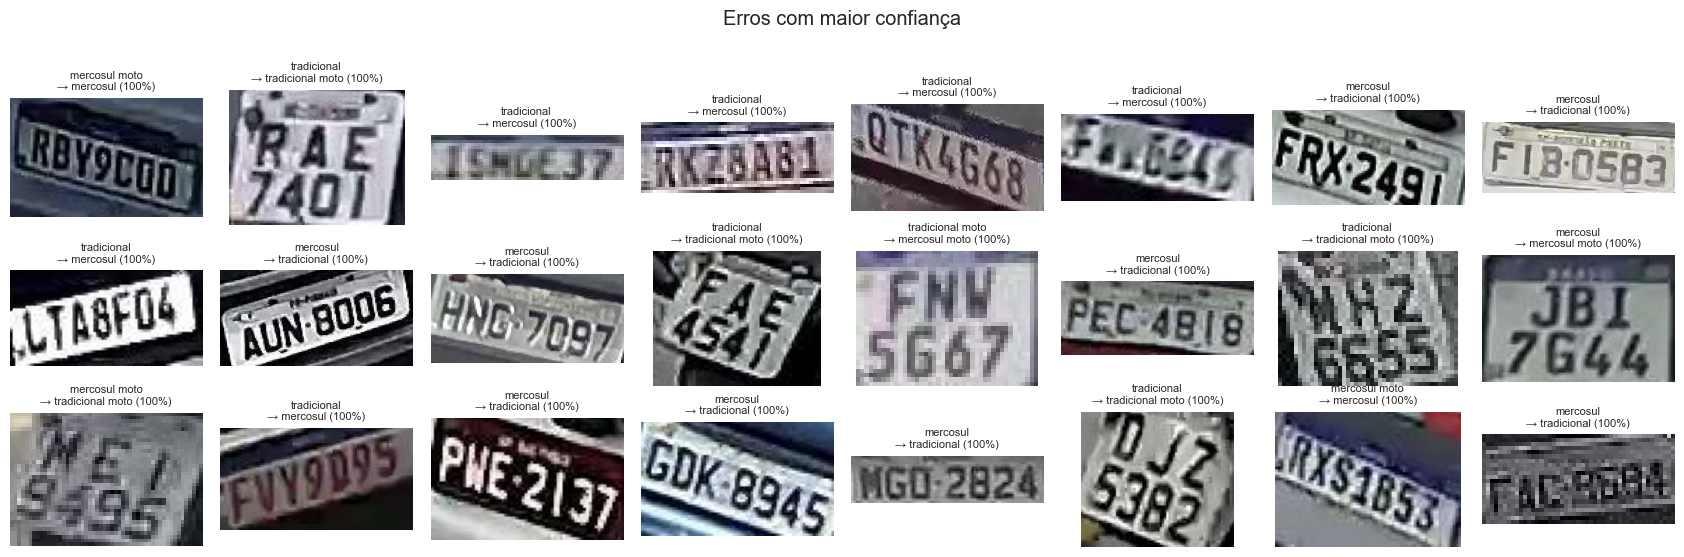

In [18]:
validacao = recortes.iloc[indices_validacao].assign(previsto=[ORDEM[i] for i in previsto], confianca=probabilidades.max(1))
erros = validacao[validacao['previsto'] != validacao['categoria']].sort_values('confianca', ascending=False)
display(erros.groupby(['categoria', 'previsto']).size().sort_values(ascending=False).rename('erros').to_frame())

fig, telas = plt.subplots(3, 8, figsize=(17, 5.5))
for tela, (_, l) in zip(telas.ravel(), erros.head(24).iterrows()):
    tela.imshow(Image.open(pasta_dados / 'validacao' / l['categoria'] / l['arquivo']))
    tela.set_title(f'{l["categoria"]}\n→ {l["previsto"]} ({l["confianca"]:.0%})', fontsize=8)
    tela.axis('off')
plt.suptitle('Erros com maior confiança', y=1.01)
plt.tight_layout()
fig.savefig(pasta_resultados / 'cnn_erros.png', dpi=120, bbox_inches='tight')
plt.show()

### Etapa 13 — Conclusões

**Modelo final:** CNN do zero com 4 blocos (conv 3×3 + BatchNorm + ReLU + MaxPool, canais 8-16-32-64), dropout 0.3 e 25 mil parâmetros. Treinada com oversampling por 15 épocas, sem aumento de dados.

| métrica (validação) | valor |
|---|---|
| acurácia | 0,914 |
| acurácia balanceada | 0,907 |
| F1 macro | 0,877 |
| recall mercosul / tradicional | 0,903 / 0,927 |
| recall mercosul moto / tradicional moto | 0,939 / 0,857 |

**Camada por camada:** o ganho vem quase todo da profundidade (1 → 4 blocos: F1 0,60 → 0,88). Depois disso, as redes maiores (até 1,2 milhão de parâmetros) quase não melhoram e decoram o treino.

**Overfitting:** a rede de 295 mil parâmetros chegava a 100% de acurácia no treino, e a perda de validação subia desde a época 4. A rede simples termina com 93,5% no treino e 91,4% na validação, e a perda de validação cai até a última época (0,31). O custo é de ~0,01 no F1 macro.

**Balanceamento:** o oversampling levou todas as categorias a 6.934 imagens no treino. Comparado ao treino sem reamostragem, ganha em F1 macro (0,877 × 0,873), em acurácia balanceada (0,907 × 0,891) e principalmente no recall da `tradicional moto` (0,857 × 0,798). O undersampling (551 por categoria) descarta 84% do treino e cai para 0,798.

**Dificuldades:**
- desbalanceamento de 12,6x: `tradicional moto` tem só 551 imagens de treino e é a categoria com pior F1 (0,77);
- recortes pequenos: 20,7% têm menos de 20 px de altura, com caracteres ilegíveis. A troca mercosul × tradicional é o erro mais comum;
- proporções muito diferentes (carro ~2,4, moto ~1,2): o redimensionamento com bordas pretas evita distorcer e mantém essa informação;
- fotos noturnas em infravermelho, sem cor: a faixa azul do Mercosul some;
- rótulos errados no dataset (motos anotadas como carro, Mercosul anotada como tradicional): parte dos erros do modelo são, na verdade, anotações erradas;
- o split do notebook 02 é por recorte, então a mesma fotografia pode ter placas no treino e na validação. Além disso, a arquitetura foi escolhida na própria validação. Um conjunto de teste separado por fotografia daria uma medida mais confiável.